# Initiating EDA

In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

In [34]:
df = pd.read_csv('../data/WeightedSentimentTelemedicineDataset.csv', low_memory=False)

## A. Data Description

FROM README.txt

List of Attribute 
    This dataset is designed to support the development of automated classification models for user reviews in telemedicine applications. It also includes additional attributes, such as weight. The list of attributes is shown in the table below. 

Attribute Description 
- platform : Application distributor platform 
- app_name : Application name 
- rating : Application user satisfaction score  
- review : Application user review 
- sentiment : Data label (negative, neutral, positive) 
- weight : User review complexity label (uninformative, informative, complex) 

Value of the Data 
- The Weighted Telemedicine Sentiment Dataset contains 19,680 manually annotated Indonesian-language user reviews from three telemedicine applications, labeled with three sentiment classes (Positive, Neutral, Negative) and a weight attribute (Uninformative, Informative, Complex) indicating review informativeness. 
- The annotation was performed by two annotators following a documented guideline reviewed by a psychology expert, with inter-annotator agreement measured using Cohen's Kappa, which indicated substantial agreement (κ = 0.752), thereby enabling other researchers to assess label reliability. 
- Facilitates and supports experiments in advanced NLP technologies, including BERT, LSTM, and LLMs, such as the user review sentiment classification task. 
- This dataset introduces a weight attribute (Uninformative, Informative, Complex), which adds a crucial secondary dimension. This enables researchers to analyze not only what the user feels but also the substantive value of the review, thereby facilitating more advanced tasks such as Aspect-Based Sentiment Analysis (ABSA). On the other hand, this label can be enabled to curate the data, such as filtering uninformative reviews or studying the characteristics of complex user feedback, while telemedicine providers can use the labeled reviews to examine user-reported service issues. 

Data Annotation 
- The dataset was manually annotated by two annotators 

- A fundamental difference from the previous dataset lies in the manual annotation process, which was validated by Psychology experts, ensuring that the resulting annotations align with scientific psychological principles 


In [35]:
df.head(5)

,platform,app_name,rating,review,sentiment,weight
0,Play Store,Alodokter —Chat Bersama Dokter,5,oke,NEUTRAL,UNINFORMATIVE
1,Play Store,Alodokter —Chat Bersama Dokter,2,"baru download, mau daftar ga bisa2. haduuhhh t...",NEGATIVE,UNINFORMATIVE
2,Play Store,Alodokter —Chat Bersama Dokter,1,mending chat sama chatgpt dari pada alodokter....,NEGATIVE,UNINFORMATIVE
3,Play Store,Alodokter —Chat Bersama Dokter,5,Sangat Memuaskan,POSITIVE,UNINFORMATIVE
4,Play Store,Alodokter —Chat Bersama Dokter,5,"saya usia 54 thn sering sakit gigi, klau sakit...",NEUTRAL,UNINFORMATIVE


In [36]:
df['platform'].value_counts()

platform
Play Store    19680
Name: count, dtype: int64

In [37]:
df['app_name'].value_counts()

app_name
Alodokter —Chat Bersama Dokter    7602
Halodoc: Dokter, Obat & Lab       7295
KlikDokter: Jaga Sehatmu          4783
Name: count, dtype: int64

In [38]:
df['weight'].value_counts()

weight
UNINFORMATIVE    16572
INFORMATIVE       2718
COMPLEX            390
Name: count, dtype: int64

### A.1 'weight' column overview

In [39]:
df[df['weight'] == 'UNINFORMATIVE']

,platform,app_name,rating,review,sentiment,weight
0,Play Store,Alodokter —Chat Bersama Dokter,5,oke,NEUTRAL,UNINFORMATIVE
1,Play Store,Alodokter —Chat Bersama Dokter,2,"baru download, mau daftar ga bisa2. haduuhhh t...",NEGATIVE,UNINFORMATIVE
2,Play Store,Alodokter —Chat Bersama Dokter,1,mending chat sama chatgpt dari pada alodokter....,NEGATIVE,UNINFORMATIVE
3,Play Store,Alodokter —Chat Bersama Dokter,5,Sangat Memuaskan,POSITIVE,UNINFORMATIVE
4,Play Store,Alodokter —Chat Bersama Dokter,5,"saya usia 54 thn sering sakit gigi, klau sakit...",NEUTRAL,UNINFORMATIVE
...,...,...,...,...,...,...
19675,Play Store,KlikDokter: Jaga Sehatmu,5,Mempermudah mngetahui tntng kshatan gaya hdup ...,POSITIVE,UNINFORMATIVE
19676,Play Store,KlikDokter: Jaga Sehatmu,5,Semua ulasan,POSITIVE,UNINFORMATIVE
19677,Play Store,KlikDokter: Jaga Sehatmu,4,BAguz,POSITIVE,UNINFORMATIVE
19678,Play Store,KlikDokter: Jaga Sehatmu,5,Mempermudah kita jika mau berkonsultasi dengan...,POSITIVE,UNINFORMATIVE


In [40]:
df[df['weight'] == 'INFORMATIVE'].head(5)

,platform,app_name,rating,review,sentiment,weight
9,Play Store,Alodokter —Chat Bersama Dokter,5,aplikasi ini engga amanah saya order yang inst...,NEGATIVE,INFORMATIVE
11,Play Store,Alodokter —Chat Bersama Dokter,1,syaa sudah konsul dokter SP.M di kasih resep o...,NEGATIVE,INFORMATIVE
16,Play Store,Alodokter —Chat Bersama Dokter,5,kapok berobat d Alo dokter obat sudah d beli G...,NEGATIVE,INFORMATIVE
29,Play Store,Alodokter —Chat Bersama Dokter,5,"GK bisa daftar, bahaya ini. mohon dicoba kemba...",NEGATIVE,INFORMATIVE
39,Play Store,Alodokter —Chat Bersama Dokter,5,"mau tanya, ini konsul doang atau konsul terus ...",NEUTRAL,INFORMATIVE


In [41]:
df[df['weight'] == 'COMPLEX'].head(5)

,platform,app_name,rating,review,sentiment,weight
42,Play Store,Alodokter —Chat Bersama Dokter,1,"setiap chat dokter, selalu je scroll otomatis ...",NEGATIVE,COMPLEX
49,Play Store,Alodokter —Chat Bersama Dokter,4,tolong memberikan deskripsi di aplikasi nya se...,POSITIVE,COMPLEX
82,Play Store,Alodokter —Chat Bersama Dokter,5,belum jg ngmong. udah habis masa pembayaran ny...,NEGATIVE,COMPLEX
96,Play Store,Alodokter —Chat Bersama Dokter,5,"Sangat terbantu dengan resep dokternya, pengir...",POSITIVE,COMPLEX
119,Play Store,Alodokter —Chat Bersama Dokter,5,tingkatkan lagi pelyananan supaya semua bisa d...,POSITIVE,COMPLEX


In [42]:
df['review_length'] = df['review'].str.len()

In [43]:
df.groupby('weight')['review_length'].describe().round(3).T

weight,COMPLEX,INFORMATIVE,UNINFORMATIVE
count,390.000,2718.000,16520.000
mean,307.359,192.678,52.208
std,116.397,99.450,42.546
min,53.000,13.000,2.000
25%,218.250,123.000,22.000
50%,287.500,172.000,40.000
75%,408.750,236.000,71.000
max,529.000,595.000,499.000


In [44]:
df[(df['review_length'] > 71) & (df['weight'] == 'UNINFORMATIVE')]

,platform,app_name,rating,review,sentiment,weight,review_length
1,Play Store,Alodokter —Chat Bersama Dokter,2,"baru download, mau daftar ga bisa2. haduuhhh t...",NEGATIVE,UNINFORMATIVE,101.0
2,Play Store,Alodokter —Chat Bersama Dokter,1,mending chat sama chatgpt dari pada alodokter....,NEGATIVE,UNINFORMATIVE,156.0
4,Play Store,Alodokter —Chat Bersama Dokter,5,"saya usia 54 thn sering sakit gigi, klau sakit...",NEUTRAL,UNINFORMATIVE,289.0
5,Play Store,Alodokter —Chat Bersama Dokter,2,dokternya responnya lama .... ( Semoga bisa di...,NEGATIVE,UNINFORMATIVE,99.0
13,Play Store,Alodokter —Chat Bersama Dokter,1,sedikit kecewa. karena psikolog saya yg salah ...,NEGATIVE,UNINFORMATIVE,156.0
...,...,...,...,...,...,...,...
19640,Play Store,KlikDokter: Jaga Sehatmu,5,sangat bermanfaat sekali buat kita dn keluarga...,POSITIVE,UNINFORMATIVE,108.0
19648,Play Store,KlikDokter: Jaga Sehatmu,5,Sangat penting buat saya untuk mengetahui tent...,POSITIVE,UNINFORMATIVE,98.0
19650,Play Store,KlikDokter: Jaga Sehatmu,4,Dengan aplikasi ini saya lebih mudah untuk men...,POSITIVE,UNINFORMATIVE,82.0
19657,Play Store,KlikDokter: Jaga Sehatmu,4,Trimakasih banyak klinik dokter.. saya sangat ...,POSITIVE,UNINFORMATIVE,136.0


### A.2 'sentiment' column overview

In [45]:
df['sentiment'].value_counts()

sentiment
POSITIVE    14748
NEGATIVE     4221
NEUTRAL       711
Name: count, dtype: int64

In [46]:
df.groupby('app_name')['sentiment'].value_counts().T

app_name                        sentiment
Alodokter —Chat Bersama Dokter  POSITIVE     4915
                                NEGATIVE     2260
                                NEUTRAL       427
Halodoc: Dokter, Obat & Lab     POSITIVE     6198
                                NEGATIVE     1030
                                NEUTRAL        67
KlikDokter: Jaga Sehatmu        POSITIVE     3635
                                NEGATIVE      931
                                NEUTRAL       217
Name: count, dtype: int64

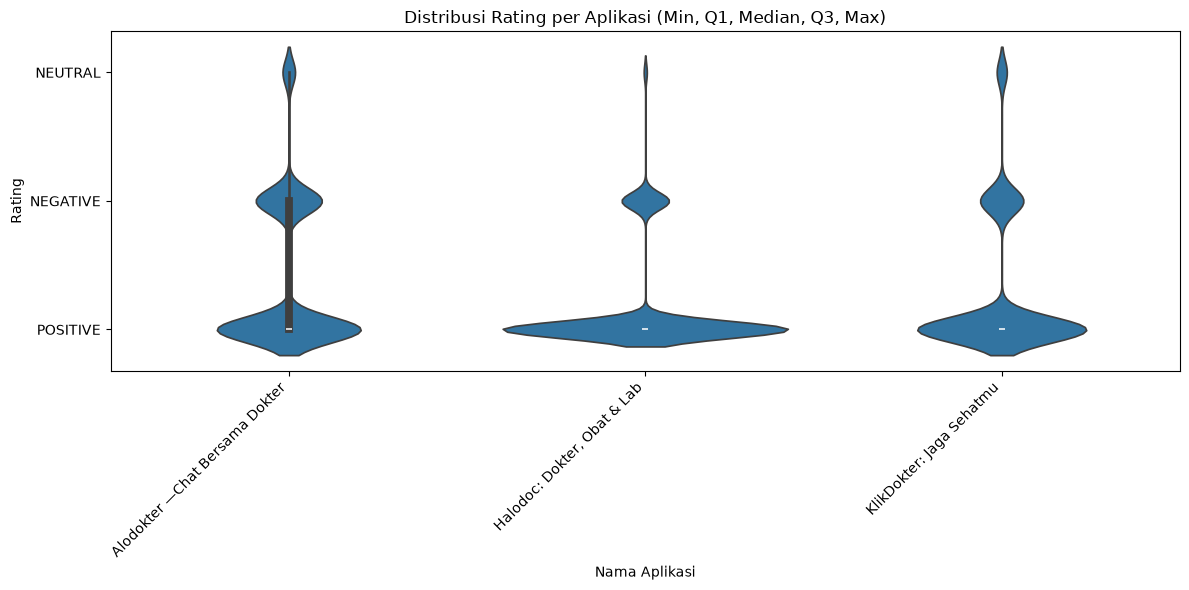

In [62]:
plt.figure(figsize=(12, 6))
sns.violinplot(data=df, x='app_name', y='sentiment')

plt.title('Distribusi Rating per Aplikasi (Min, Q1, Median, Q3, Max)')
plt.xlabel('Nama Aplikasi')
plt.ylabel('Rating')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

### A.3 Rating score overview 
based on each App review

In [48]:
df.groupby('app_name')['rating'].describe().T

app_name,Alodokter —Chat Bersama Dokter,"Halodoc: Dokter, Obat & Lab",KlikDokter: Jaga Sehatmu
count,7602.000000,7295.000000,4783.000000
mean,3.830571,4.426456,4.133807
std,1.696626,1.297648,1.468074
min,1.000000,1.000000,1.000000
25%,2.000000,5.000000,4.000000
50%,5.000000,5.000000,5.000000
75%,5.000000,5.000000,5.000000
max,5.000000,5.000000,5.000000


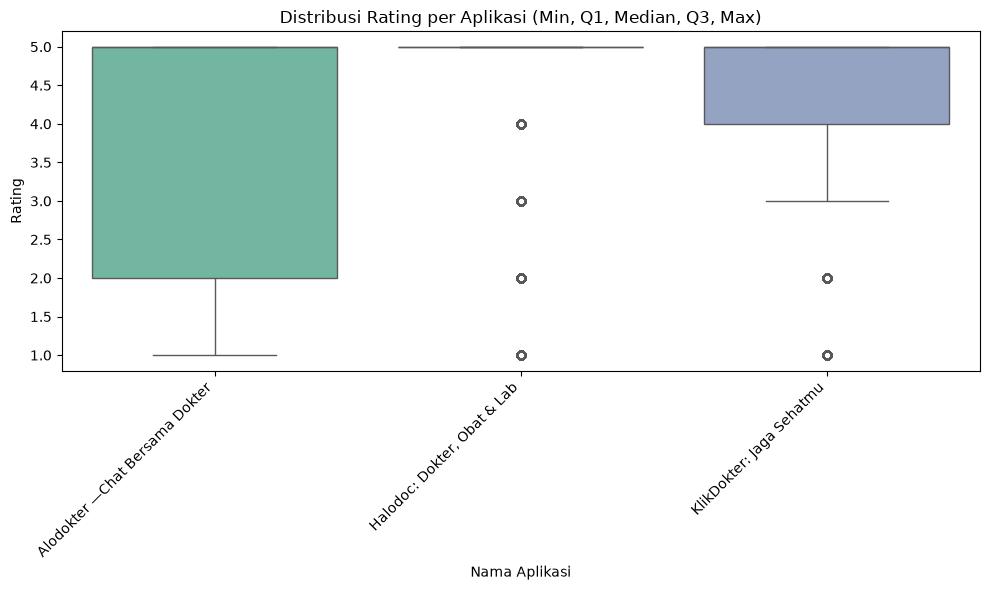

In [49]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x='app_name', y='rating', palette='Set2')

plt.title('Distribusi Rating per Aplikasi (Min, Q1, Median, Q3, Max)')
plt.xlabel('Nama Aplikasi')
plt.ylabel('Rating')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## B. Vectorization